In [1]:
from mypackages import *

In [2]:
df = pd.read_csv('cleaned data.csv')
df.head()

,variable 1,variable 2,Output
0,30,30,2315.7
1,30,35,1932.6
2,30,40,1592.2
3,30,45,1316.6
4,30,50,1099.5


In [3]:
var1 = df['variable 1'].unique()

In [4]:
len(var1)

25

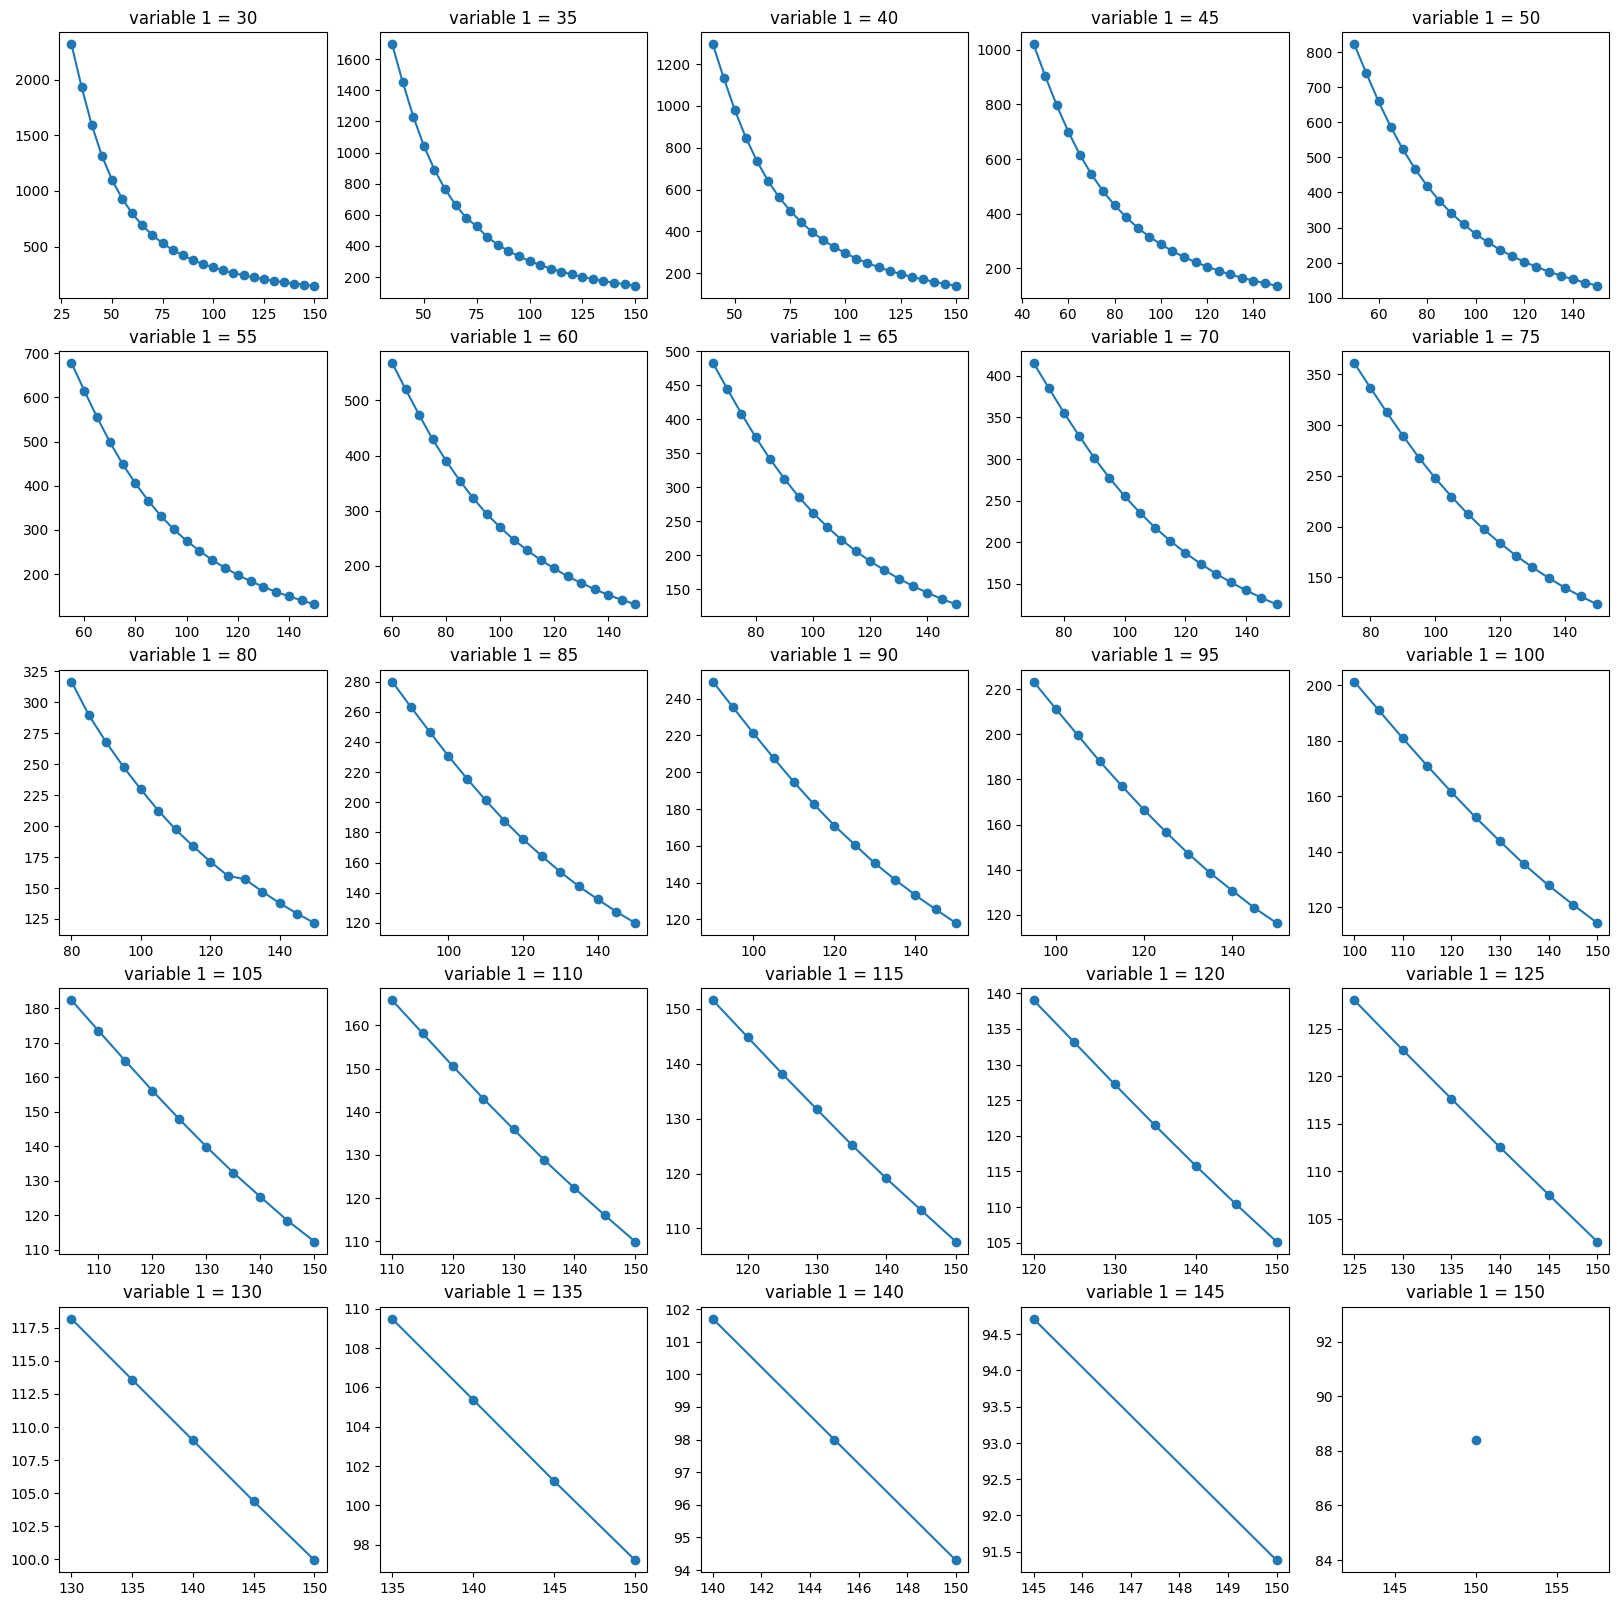

In [5]:
fig,ax = plt.subplots(5,5, figsize = (20,20))

for i in range(5):
    for j in range(5):
        temp = df[df['variable 1'] == var1[5*i+j]]
        ax[i,j].plot(temp['variable 2'], temp['Output'], marker = 'o')
        ax[i,j].set_title('variable 1 = '+str(var1[5*i+j]))

plt.show()

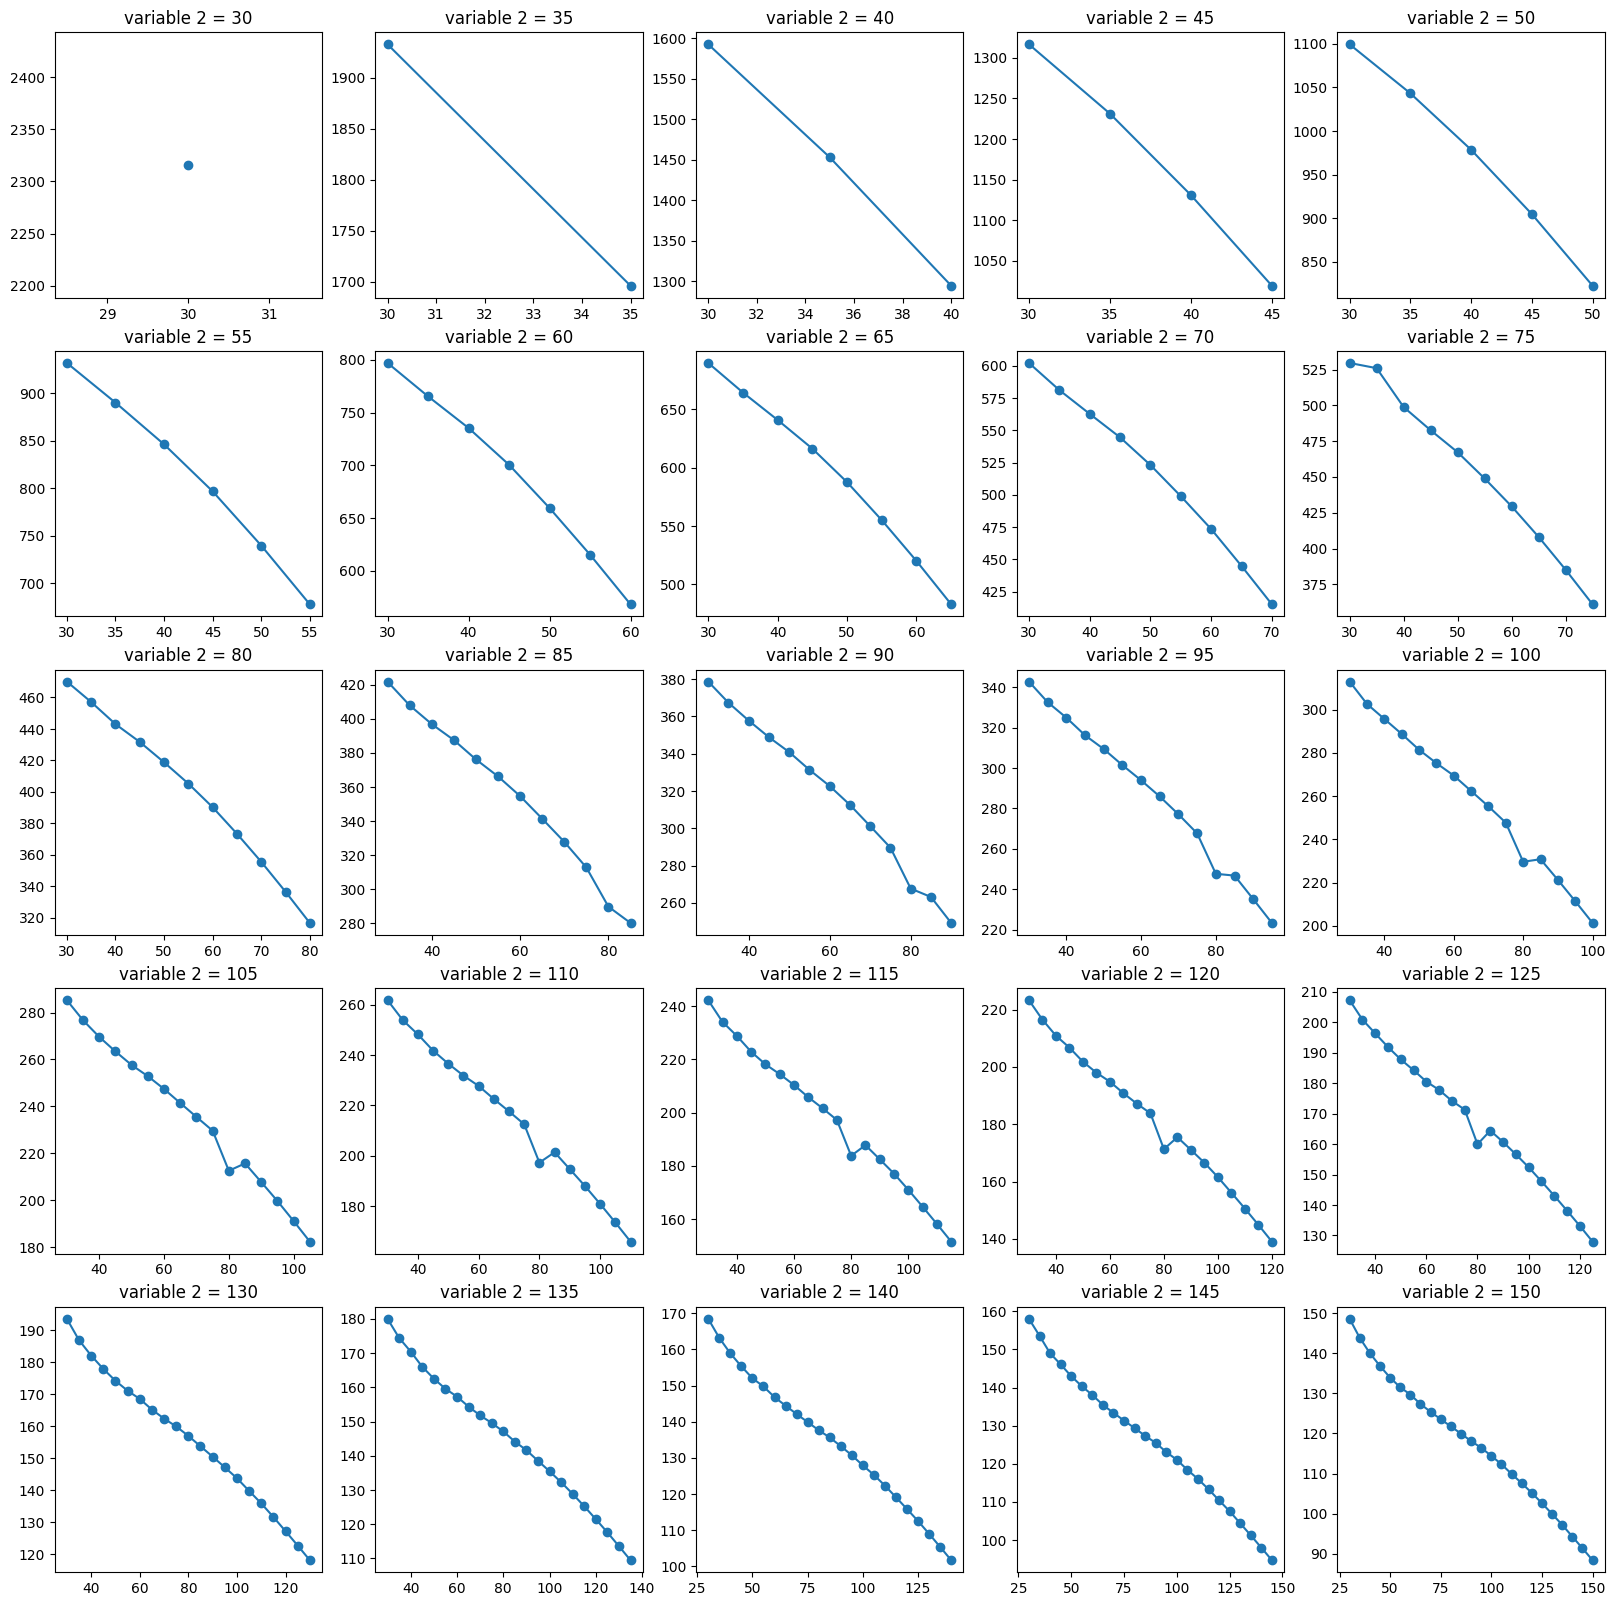

In [6]:
var2 = df['variable 2'].unique()
fig,ax = plt.subplots(5,5, figsize = (20,20))

for i in range(5):
    for j in range(5):
        temp = df[df['variable 2'] == var2[5*i+j]]
        ax[i,j].plot(temp['variable 1'], temp['Output'], marker = 'o')
        ax[i,j].set_title('variable 2 = '+str(var2[5*i+j]))

plt.show()

3D plot of Data

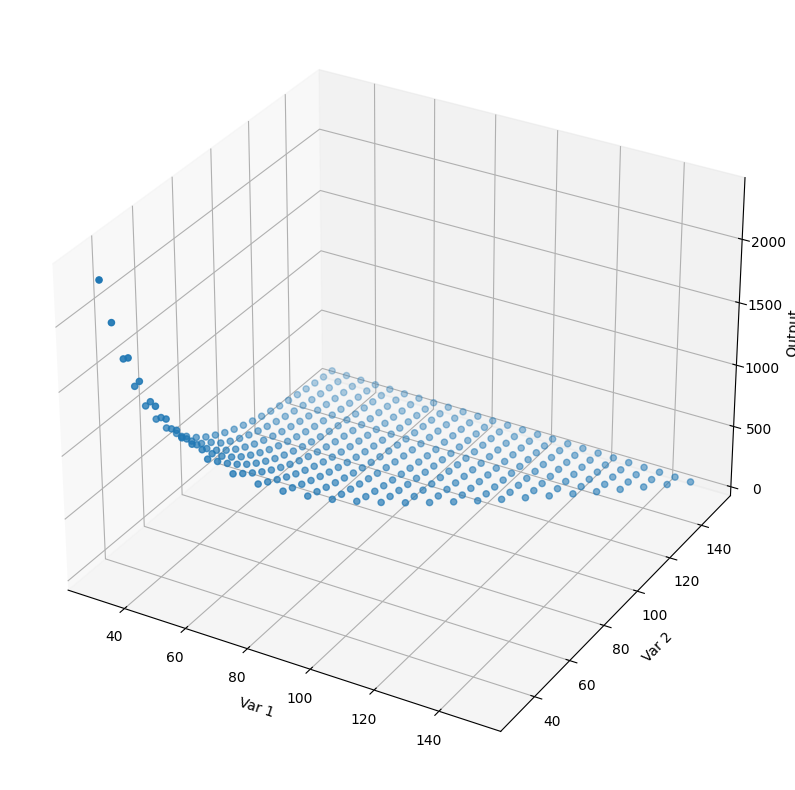

In [7]:
fig = plt.figure(figsize = (10,10))
ax = fig.add_subplot(projection = '3d')
ax.scatter(df['variable 1'], df['variable 2'], df['Output'], marker = 'o')
ax.set_xlabel('Var 1')
ax.set_ylabel('Var 2')
ax.set_zlabel('Output')
plt.show()

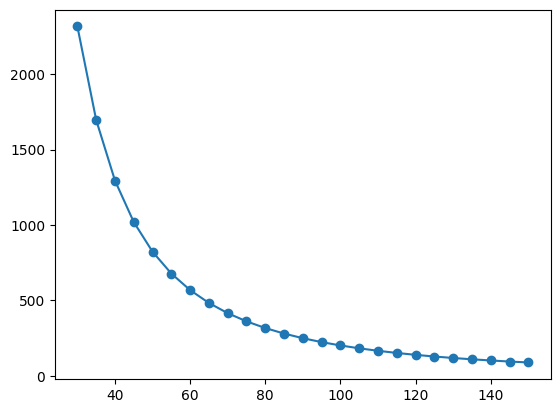

In [8]:
diag = df[df['variable 1'] == df['variable 2']]
plt.plot(diag['variable 1'], diag['Output'], marker = 'o')

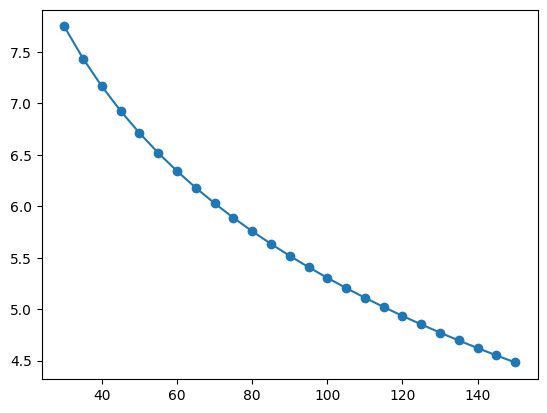

In [9]:
plt.plot(diag['variable 1'], np.log(diag['Output']), marker = 'o')

## Multivariate model

In [10]:
df.head()

,variable 1,variable 2,Output
0,30,30,2315.7
1,30,35,1932.6
2,30,40,1592.2
3,30,45,1316.6
4,30,50,1099.5


In [11]:
X = df.drop(columns = ['Output']).to_numpy().T
Z = df['Output'].to_numpy()

In [12]:
def model_eq(X,k1,k2,k3,k4,k5,k6,k7):
    y,x = X
    return k2*y*np.exp(-k1*x) + k3*np.exp(-k1*x) - k4*x*y + k5*x + k6*y + k7

p0 = [0.1, 1.0, 1.0, 0., 0., 0., 0.]
lower_bounds = [0.001, -np.inf, -np.inf, -np.inf, -np.inf, -np.inf, -np.inf]
upper_bounds = [np.inf, np.inf, np.inf, np.inf, np.inf, np.inf, np.inf]
bounds = (lower_bounds, upper_bounds)



# def model_eq(X,m,f,A,k,B,C,D):
#     y,x = X
#     z = (y-f)/m
#     return (A*np.exp(-k*x)+B) * z + (C*x+D) * (1-z)


# p0 = [1.0, 1.0, 1.0, 0.1, 25, -0.5, 5.0]
# lower_bounds = [-np.inf, -np.inf, -np.inf, 0.001, -np.inf, -np.inf, -np.inf]
# upper_bounds = [np.inf, np.inf, np.inf, np.inf, np.inf, np.inf, np.inf]
# bounds = (lower_bounds, upper_bounds)

popt,pcov = scipy.optimize.curve_fit(model_eq,X,Z,p0 = p0, bounds = bounds)

In [13]:
popt

array([ 4.63869723e-02, -1.18760529e+02,  1.10415421e+04, -3.69927567e-03,
       -2.52547674e+00, -8.50445498e-01,  5.13734528e+02])

In [14]:
Z_pred = model_eq(X,*popt)

In [15]:
df['Z_pred'] = Z_pred

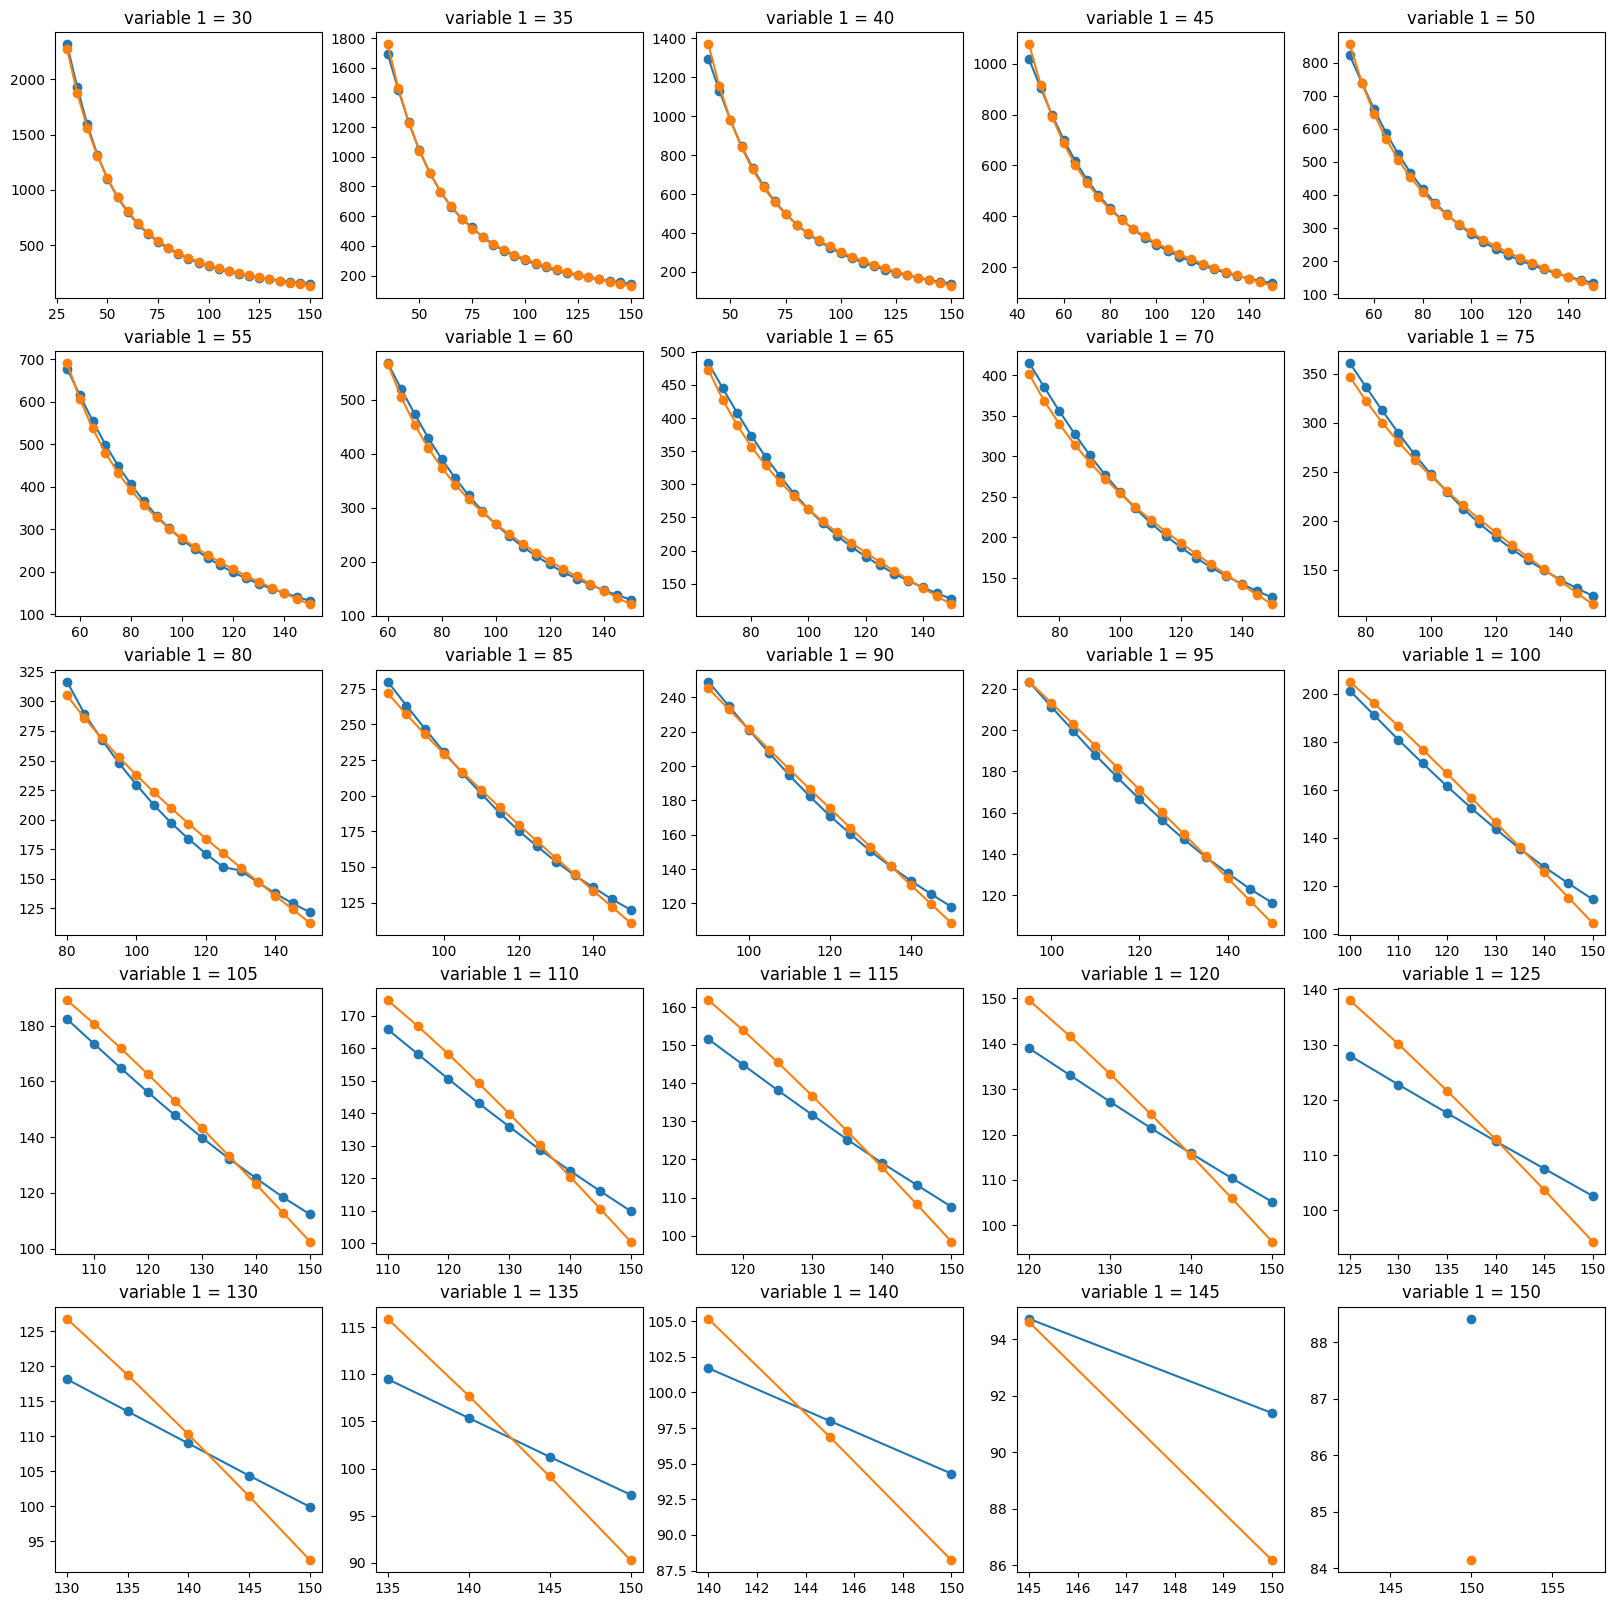

In [16]:
fig,ax = plt.subplots(5,5, figsize = (20,20))

for i in range(5):
    for j in range(5):
        temp = df[df['variable 1'] == var1[5*i+j]]
        ax[i,j].plot(temp['variable 2'], temp['Output'], marker = 'o')
        ax[i,j].plot(temp['variable 2'], temp['Z_pred'], marker = 'o')
        ax[i,j].set_title('variable 1 = '+str(var1[5*i+j]))

plt.show()

In [17]:
mean_squared_error(Z_pred,Z)

113.79039603806068

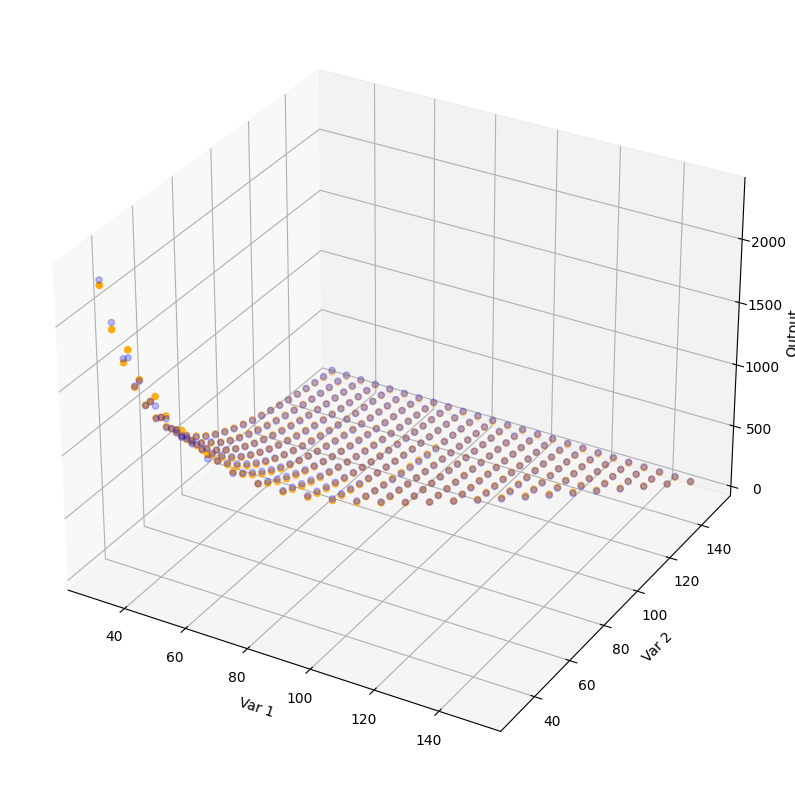

In [18]:
fig = plt.figure(figsize = (10,10))
ax = fig.add_subplot(projection = '3d')
ax.scatter(df['variable 1'], df['variable 2'], df['Output'], marker = 'o', color = 'blue', alpha = 0.25)
ax.scatter(df['variable 1'], df['variable 2'], df['Z_pred'], marker = 'o', color = 'orange')
ax.set_xlabel('Var 1')
ax.set_ylabel('Var 2')
ax.set_zlabel('Output')
plt.show()